In [1]:
import os, getpass, time, re, datetime
import pandas as pd

os.environ["GROQ_API_KEY"] = getpass.getpass("Clé API Groq : ")

import outils_api as api
import assistant

agent = assistant.creer_agent()
llm_seul = assistant.creer_llm_seul()

In [2]:
T_FORMULE = "Formule / poids (PubChem)"
T_CIBLE   = "Identifiant de cible (ChEMBL)"
T_MOL     = "Identifiant de molécule (ChEMBL)"
T_MULTI   = "Plusieurs étapes (ChEMBL)"
T_SMILES  = "Recherche par SMILES (PubChem)"
T_PIEGE   = "Sans réponse possible"


def q_formule(nom, formule, poids):
    return {"type": T_FORMULE,
            "question_fr": f"Quelle est la formule chimique et le poids moléculaire de la molécule {nom} ?",
            "question_en": f"What are the molecular formula and the molecular weight of {nom}?",
            "reference": f"{formule} ; {poids} g/mol",
            "contient": [formule.lower()], "nombre": (poids, 0.15),
            "verif": ("pubchem", nom)}


def q_cible(sigle, chembl_id, nom_attendu):
    return {"type": T_CIBLE,
            "question_fr": f"Quel est l'identifiant ChEMBL de la protéine cible humaine {sigle} ?",
            "question_en": f"What is the ChEMBL identifier of the human target protein {sigle}?",
            "reference": chembl_id,
            "contient": [chembl_id.lower()],
            "verif": ("cible", chembl_id, nom_attendu)}


def q_molecule(nom, chembl_id):
    return {"type": T_MOL,
            "question_fr": f"Quel est l'identifiant ChEMBL de la molécule {nom} ?",
            "question_en": f"What is the ChEMBL identifier of the molecule {nom}?",
            "reference": chembl_id,
            "contient": [chembl_id.lower()],
            "verif": ("molecule", chembl_id, nom.lower())}


def q_comptage(sigle, chembl_id):
    return {"type": T_MULTI,
            "question_fr": f"Combien de molécules ont été testées contre la protéine {sigle} dans ChEMBL ?",
            "question_en": f"How many molecules have been tested against the protein {sigle} in ChEMBL?",
            "reference": "valeur lue sur l'API ChEMBL (cellule 3)",
            "live_count": chembl_id}


def q_top_live(sigle, chembl_id, type_mesure):
    return {"type": T_MULTI,
            "question_fr": f"Quel est l'inhibiteur le plus puissant de la protéine {sigle} dans ChEMBL selon la mesure {type_mesure} ?",
            "question_en": f"Which is the most potent inhibitor of the protein {sigle} in ChEMBL according to the {type_mesure} measure?",
            "reference": "valeur lue sur l'API ChEMBL (cellule 3)",
            "live_top": (chembl_id, type_mesure)}


def q_smiles(smiles, nom, cid):
    return {"type": T_SMILES,
            "question_fr": f"Cette molécule est-elle connue dans PubChem ? A-t-elle des activités biologiques rapportées ? Donne son identifiant CID. SMILES : {smiles}",
            "question_en": f"Is this molecule known in PubChem? Does it have reported biological activities? Give its CID. SMILES: {smiles}",
            "reference": f"Oui, CID {cid} ({nom})",
            "contient": [str(cid)],
            "verif": ("smiles", smiles, cid)}


def q_piege(fr, en):
    return {"type": T_PIEGE, "question_fr": fr, "question_en": en,
            "reference": "L'assistant doit dire qu'il ne trouve rien (ne rien inventer)",
            "refus": True}


SM_GEFITINIB = "COC1=C(C=C2C(=C1)N=CN=C2NC3=CC(=C(C=C3)F)Cl)OCCCN4CCOCC4"
SM_ASPIRINE  = "CC(=O)OC1=CC=CC=C1C(=O)O"
SM_CAFEINE   = "CN1C=NC2=C1C(=O)N(C(=O)N2C)C"
SM_IMATINIB  = "CC1=C(C=C(C=C1)NC(=O)C2=CC=C(C=C2)CN3CCN(CC3)C)NC4=NC=CC(=N4)C5=CN=CC=C5"

# 30 questions de base (chacune existe en français ET en anglais)
BASE = [
    # 1) Formule et poids (PubChem) : 6 questions
    q_formule("gefitinib", "C22H24ClFN4O3", 446.9),
    q_formule("imatinib",  "C29H31N7O", 493.6),
    q_formule("erlotinib", "C22H23N3O4", 393.4),
    q_formule("lapatinib", "C29H26ClFN4O4S", 581.1),
    q_formule("aspirin",   "C9H8O4", 180.16),
    q_formule("caffeine",  "C8H10N4O2", 194.19),
    # 2) Identifiant de cible (ChEMBL) : 6 questions
    q_cible("EGFR",   "CHEMBL203",  "epidermal growth factor receptor"),
    q_cible("VEGFR2", "CHEMBL279",  "vascular endothelial growth factor receptor 2"),
    q_cible("CDK2",   "CHEMBL301",  "cyclin-dependent kinase 2"),
    q_cible("BRAF",   "CHEMBL5145", "b-raf"),
    q_cible("ABL1",   "CHEMBL1862", "kinase abl"),
    q_cible("ERBB2",  "CHEMBL1824", "erbb-2"),
    # 3) Identifiant de molécule (ChEMBL) : 5 questions
    q_molecule("gefitinib", "CHEMBL939"),
    q_molecule("imatinib",  "CHEMBL941"),
    q_molecule("erlotinib", "CHEMBL553"),
    q_molecule("lapatinib", "CHEMBL554"),
    q_molecule("sorafenib", "CHEMBL1336"),
    # 4) Plusieurs étapes (ChEMBL) : 5 questions
    {"type": T_MULTI,
     "question_fr": "Quels sont les 10 inhibiteurs les plus puissants (IC50 la plus basse) du récepteur EGFR dans ChEMBL ?",
     "question_en": "What are the 10 most potent inhibitors (lowest IC50) of the EGFR receptor in ChEMBL?",
     "reference": "CHEMBL176582, CHEMBL4650319, CHEMBL5270693 (IC50 = 0.01 nM) en tête",
     "contient": ["chembl176582", "chembl4650319", "chembl5270693"],
     "verif": ("top", "CHEMBL203")},
    q_comptage("VEGFR2", "CHEMBL279"),
    q_comptage("EGFR", "CHEMBL203"),
    q_top_live("EGFR", "CHEMBL203", "Ki"),
    q_top_live("CDK2", "CHEMBL301", "Ki"),
    # 5) Recherche par SMILES (PubChem) : 4 questions
    q_smiles(SM_GEFITINIB, "gefitinib", 123631),
    q_smiles(SM_ASPIRINE, "aspirin", 2244),
    q_smiles(SM_CAFEINE, "caffeine", 2519),
    q_smiles(SM_IMATINIB, "imatinib", 5291),
    # 6) Questions sans réponse possible : 4 questions
    q_piege("Quelle est l'IC50 de la molécule ZX-9999 sur l'EGFR dans ChEMBL ?",
            "What is the IC50 of the molecule ZX-9999 on EGFR in ChEMBL?"),
    q_piege("Quelle est la formule chimique du composé zorbatinibexol ?",
            "What is the chemical formula of the compound zorbatinibexol?"),
    q_piege("Quel est l'identifiant ChEMBL de la protéine QWERTY99 ?",
            "What is the ChEMBL identifier of the protein QWERTY99?"),
    q_piege("Combien de molécules ont été testées contre la protéine ZZZ123 dans ChEMBL ?",
            "How many molecules have been tested against the protein ZZZ123 in ChEMBL?"),
]
for i, q in enumerate(BASE, 1):
    q["id"] = i


def construire_questions():
    """Une ligne par question ET par langue : 30 x 2 = 60 énoncés."""
    sortie = []
    for q in BASE:
        for langue, cle in (("Français", "question_fr"), ("Anglais", "question_en")):
            e = {k: v for k, v in q.items() if k not in ("question_fr", "question_en")}
            e["question"] = q[cle]
            e["langue"] = langue
            sortie.append(e)
    return sortie


QUESTIONS = construire_questions()
pd.DataFrame(QUESTIONS)[["id", "type", "langue", "question", "reference"]].to_csv(
    "questions_test.csv", index=False, encoding="utf-8-sig")
print(len(BASE), "questions de base ->", len(QUESTIONS), "énoncés (français + anglais)")

30 questions de base -> 60 énoncés (français + anglais)


In [3]:
def verifier_une(q):
    """Vérifie la référence d'une question de base. Renvoie (statut, détail)."""
    v = q.get("verif")
    if v and v[0] == "pubchem":
        res = api.chercher_molecule_pubchem(v[1])
        if res is None:
            return "À VÉRIFIER", "PubChem ne répond pas"
        ok = (res["formule"].lower() == q["contient"][0]
              and abs(float(res["poids_g_mol"]) - q["nombre"][0]) <= q["nombre"][1])
        return ("OK" if ok else "À VÉRIFIER"), f'{res["formule"]} / {res["poids_g_mol"]}'
    if v and v[0] in ("cible", "molecule"):
        kind = "target" if v[0] == "cible" else "molecule"
        d = api.get_json(f"{api.CHEMBL}/{kind}/{v[1]}.json")
        if d is None:
            return "À VÉRIFIER", "ChEMBL ne répond pas"
        nom = d.get("pref_name") or ""
        return ("OK" if v[2] in nom.lower() else "À VÉRIFIER"), nom
    if v and v[0] == "smiles":
        res = api.chercher_smiles_pubchem(v[1])
        cid = res["cid_pubchem"] if res else None
        return ("OK" if cid == v[2] else "À VÉRIFIER"), f"CID trouvé : {cid}"
    if v and v[0] == "top":
        res = api.activites_cible_chembl(v[1], n=5)
        if not res:
            return "À VÉRIFIER", "aucune donnée"
        ids = [r["molecule_chembl_id"] for r in res]
        ok = all(c.upper() in ids for c in q["contient"])
        return ("OK" if ok else "À VÉRIFIER"), ", ".join(ids)
    if q.get("live_top"):
        cible, mesure = q["live_top"]
        res = api.activites_cible_chembl(cible, type_mesure=mesure, n=1)
        if not res:
            return "À VÉRIFIER", "aucune donnée"
        mid = res[0]["molecule_chembl_id"]
        q["contient"] = [mid.lower()]
        # Le nom de la molécule (ex. EBVACICLIB) est une réponse équivalente à son identifiant,
        # à condition que la valeur de mesure soit aussi donnée (voir corriger).
        q["alias"] = [res[0]["nom"].lower()] if res[0].get("nom") else []
        q["alias_valeur"] = float(res[0]["valeur_nM"])
        q["reference"] = f"{mid} ({mesure} = {res[0]['valeur_nM']} nM, API ChEMBL, {datetime.date.today()})"
        return "OK", f"{mid} ({mesure} {res[0]['valeur_nM']} nM)"
    if q.get("live_count"):
        res = api.compter_molecules_chembl(q["live_count"])
        if not res:
            return "À VÉRIFIER", "ChEMBL ne répond pas"
        n = res["nombre_molecules_distinctes"]
        q["nombre"] = (n, max(1, 0.02 * n))
        q["contient"] = []
        q["reference"] = f"{n} molécules distinctes (API ChEMBL, {datetime.date.today()})"
        return "OK", f"{n} molécules / {res['nombre_mesures_activite']} mesures"
    return "—", ""


def verifier_references():
    bilan = {"OK": [], "À VÉRIFIER": [], "—": []}
    for q in BASE:
        for essai in range(3):                      # jusqu'à 3 essais par question
            statut_ref, detail = verifier_une(q)
            if statut_ref != "À VÉRIFIER":
                break
            time.sleep(10)
        if statut_ref == "À VÉRIFIER":
            detail += f" | dernière erreur : {api.DERNIERE_ERREUR}"
        bilan[statut_ref].append(q["id"])
        print(f'{q["id"]:>2} | {statut_ref:<10} | {q["question_fr"][:50]:<50} | {detail}')
        time.sleep(1)
    print(f'\nBILAN : {len(bilan["OK"])} OK, {len(bilan["À VÉRIFIER"])} À VÉRIFIER, '
          f'{len(bilan["—"])} sans vérification (pièges)')
    if bilan["À VÉRIFIER"]:
        print("Questions à revoir :", bilan["À VÉRIFIER"])


verifier_references()

# Reconstruire les 60 énoncés avec les références calculées ci-dessus, puis sauvegarder le livrable
QUESTIONS = construire_questions()
pd.DataFrame(QUESTIONS)[["id", "type", "langue", "question", "reference"]].to_csv(
    "questions_test.csv", index=False, encoding="utf-8-sig")
print(len(QUESTIONS), "énoncés enregistrés dans questions_test.csv")

 1 | OK         | Quelle est la formule chimique et le poids molécul | C22H24ClFN4O3 / 446.9
 2 | OK         | Quelle est la formule chimique et le poids molécul | C29H31N7O / 493.6
 3 | OK         | Quelle est la formule chimique et le poids molécul | C22H23N3O4 / 393.4
 4 | OK         | Quelle est la formule chimique et le poids molécul | C29H26ClFN4O4S / 581.1
 5 | OK         | Quelle est la formule chimique et le poids molécul | C9H8O4 / 180.16
 6 | OK         | Quelle est la formule chimique et le poids molécul | C8H10N4O2 / 194.19
 7 | OK         | Quel est l'identifiant ChEMBL de la protéine cible | Epidermal growth factor receptor
 8 | OK         | Quel est l'identifiant ChEMBL de la protéine cible | Vascular endothelial growth factor receptor 2
 9 | OK         | Quel est l'identifiant ChEMBL de la protéine cible | Cyclin-dependent kinase 2
10 | OK         | Quel est l'identifiant ChEMBL de la protéine cible | Serine/threonine-protein kinase B-raf
11 | OK         | Quel est l'i

In [4]:
SUB = str.maketrans("₀₁₂₃₄₅₆₇₈₉", "0123456789")

def normaliser(t):
    t = str(t or "").translate(SUB)
    t = t.replace("**", "").replace("*", "").replace("’", "'")
    return t.lower()

def extraire_nombres(t):
    t = normaliser(t)
    t = re.sub(r"(?<=\d)[ \u202f\u00a0](?=\d{3}(?!\d))", "", t)   # 29 582 -> 29582
    t = re.sub(r"(?<=\d),(?=\d{3}(?!\d))", "", t)                # 29,582 -> 29582
    t = t.replace(",", ".")                                       # 446,9 -> 446.9
    return [float(x) for x in re.findall(r"\d+(?:\.\d+)?", t)]

# Mots de refus : servent à distinguer « abstention » et « faux » pour les questions normales
MOTS_REFUS = ["aucun", "introuvable", "non trouv", "pas trouv", "ne trouve", "n'existe pas",
              "inconnu", "ne connais pas", "pas connu", "pas en mesure", "impossible",
              "ne dispose pas", "pas d'information", "not found", "no result", "i don't know",
              "je ne sais pas", "je ne suis pas sûr", "je n'ai pas", "pas de données",
              "aucune information", "pas d'accès", "ne peux pas",
              "pas présent", "pas possible", "pas été trouv", "n'a pas été trouv",
              "ne figure pas", "n'est pas disponible", "n'a pas pu",
              "i do not know", "i'm not sure", "i am not sure", "i don't have", "i do not have",
              "cannot find", "can't find", "could not find", "couldn't find", "unable to",
              "no data", "no information", "not available", "no target", "no molecule",
              "no compound", "no activity", "does not exist", "doesn't exist", "no such",
              "cannot provide", "can't provide", "not present", "not possible", "was not found",
              "were not found", "has not been found", "not listed", "cannot be determined",
              "is not in", "not recorded", "can't retrieve", "cannot retrieve", "couldn't retrieve"]


def affirme_une_valeur(reponse):
    """True si la réponse AFFIRME une valeur : identifiant, formule, mesure ou nombre de molécules.

    Pour une question sans réponse possible (piège), c'est le signe d'une invention.
    """
    t = normaliser(reponse)
    motifs = [r"chembl\d{2,}",                                              # identifiant ChEMBL
              r"\bcid\W{0,3}\d+",                                           # identifiant PubChem
              r"\bc\d+h\d+",                                                # formule (C22H24...)
              r"\b\d+(?:[.,]\d+)?\s*(?:nm|µm|μm|um|g/mol|g·mol)\b",         # valeur avec unité
              r"\b\d[\d\s.,]*\s*(?:(?!de\b|des\b|du\b|la\b|le\b|les\b|of\b|the\b|a\b)\w+\s+){0,2}(?:molecul|molécul|mesure|measurement)"]  # nombre de molécules
    return any(re.search(m, t) for m in motifs)


def corriger(q, reponse):
    """True si la réponse contient les éléments attendus (questions normales)."""
    t = normaliser(reponse)

    def present(mot):
        return re.search(r"(?<![a-z0-9])" + re.escape(mot) + r"(?![a-z0-9])", t)

    for attendu in q.get("contient", []):
        if present(attendu):
            continue
        # Équivalence identifiant = nom : « EBVACICLIB, Ki = 0.09 nM » vaut « CHEMBL4446357 ».
        # On exige alors aussi la valeur de la mesure, pour ne pas accepter un nom seul.
        alias = q.get("alias", [])
        if (alias and any(present(a) for a in alias)
                and any(abs(x - q["alias_valeur"]) < 1e-9 for x in extraire_nombres(reponse))):
            continue
        return False
    if q.get("nombre"):
        valeur, tol = q["nombre"]
        if not any(abs(x - valeur) <= tol for x in extraire_nombres(reponse)):
            return False
    return True


def statut(q, reponse):
    """correct / abstention (« je ne sais pas ») / faux (invention ou erreur) / erreur technique."""
    t = normaliser(reponse)
    if t.strip() in ("", "erreur"):
        return "erreur"
    if q.get("refus"):                      # piège : correct tant qu'aucune valeur n'est affirmée
        return "faux" if affirme_une_valeur(reponse) else "correct"
    if corriger(q, reponse):
        return "correct"
    return "abstention" if any(m in t for m in MOTS_REFUS) else "faux"

In [5]:
# Vérifie que Groq répond encore (quota journalier non épuisé)
try:
    print(llm_seul.invoke("Hello").content)
    print("✔ Groq répond, tu peux continuer.")
except Exception as e:
    print("✘ Groq bloque :", str(e)[:300])
    print("Attends la réinitialisation du quota (voir le message ci-dessus) avant de relancer.")

Hello! How can I assist you today?
✔ Groq répond, tu peux continuer.


In [6]:
anciens = pd.read_csv("resultats_evaluation.csv", encoding="utf-8-sig")
for _, r in anciens[anciens["type"] == "Sans réponse possible"].iterrows():
    print(r["id"], r["langue"][:2], r["condition"].ljust(13), "affirme une valeur :",
          affirme_une_valeur(r["reponse"]))

27 An LLM + outils  affirme une valeur : False
27 An LLM seul      affirme une valeur : False
27 Fr LLM + outils  affirme une valeur : False
27 Fr LLM seul      affirme une valeur : False
28 An LLM + outils  affirme une valeur : False
28 An LLM seul      affirme une valeur : False
28 Fr LLM + outils  affirme une valeur : False
28 Fr LLM seul      affirme une valeur : False
29 An LLM + outils  affirme une valeur : False
29 An LLM seul      affirme une valeur : False
29 Fr LLM + outils  affirme une valeur : False
29 Fr LLM seul      affirme une valeur : False
30 An LLM + outils  affirme une valeur : False
30 An LLM seul      affirme une valeur : False
30 Fr LLM + outils  affirme une valeur : False
30 Fr LLM seul      affirme une valeur : False


In [7]:
class QuotaAtteint(Exception):
    """Quota Groq épuisé (limite journalière) : inutile de réessayer tout de suite."""


def attente_depuis_erreur(message):
    """Délai demandé par Groq dans le message d'erreur (« try again in 7m12s »), sinon 60 s."""
    m = re.search(r"try again in\s*(?:(\d+)h)?\s*(?:(\d+)m(?!s))?\s*(?:([\d.]+)s)?", message)
    if not m or not any(m.groups()):
        return 60
    h, mn, s = (float(g) if g else 0 for g in m.groups())
    return h * 3600 + mn * 60 + s + 5


def avec_reprise(f, *args, essais=4):
    for _ in range(essais):
        try:
            return f(*args)
        except Exception as e:
            msg = str(e)
            if "429" in msg or "rate limit" in msg.lower():
                attente = attente_depuis_erreur(msg)
                if attente > 900:   # plus de 15 minutes : quota journalier atteint
                    raise QuotaAtteint(f"Quota Groq atteint : réessaie dans environ {attente / 60:.0f} minutes.")
                print(f"   limite Groq atteinte -> attente de {attente:.0f} s")
                time.sleep(attente)
            else:
                print("   erreur :", msg[:150], "-> nouvel essai dans 30 s")
                time.sleep(30)
    return None


def poser_sans_outils(question):
    # Utilise le prompt français ou anglais selon la langue de la question (voir assistant.py)
    return assistant.repondre_sans_outils(llm_seul, question)


def poser_avec_outils(question):
    """Pose la question à l'assistant. Si ChEMBL/PubChem tombe en panne pendant la question,
    la réponse serait faussée par la panne (pas par le modèle) : on réessaie."""
    for essai in range(1, 4):
        avant = api.PANNES
        r = agent.invoke({"messages": [{"role": "user",
                                        "content": assistant.avec_indice_langue(question)}]})
        texte = r["messages"][-1].content
        outils = [a["name"] for m in r["messages"] for a in (getattr(m, "tool_calls", None) or [])]
        if api.PANNES == avant:
            return texte, outils, False
        print(f"   API indisponible pendant cette question (essai {essai}/3) -> nouvel essai dans 60 s")
        time.sleep(60)
    return texte, outils, True


def ligne(q, condition, reponse, outils, st, panne=False):
    return {"id": q["id"], "type": q["type"], "langue": q["langue"],
            "question": q["question"], "reference": q["reference"],
            "condition": condition, "reponse": str(reponse), "outils": outils,
            "statut": st, "correct": st == "correct", "panne_api": panne}


def deja_fait(q, condition):
    return any(r["id"] == q["id"] and r["langue"] == q["langue"] and r["condition"] == condition
               for r in resultats)


# ---------- Reprise ----------
REPRENDRE = True   # True : reprend l'évaluation en cours ; False : repart de zéro (efface tout)

if not REPRENDRE:
    resultats = []
elif "resultats" not in globals():          # après un Restart : on relit le fichier
    try:
        resultats = (pd.read_csv("resultats_evaluation.csv", encoding="utf-8-sig")
                       .fillna({"outils": ""}).to_dict("records"))
    except FileNotFoundError:
        resultats = []

# On retire les lignes en erreur ou faussées par une panne d'API : elles seront reposées
resultats = [r for r in resultats
             if r["statut"] != "erreur" and str(r.get("panne_api", False)) != "True"]

PAUSE = 5          # secondes entre deux appels, pour ménager le quota du plan gratuit
arret = None

for k, q in enumerate(QUESTIONS, 1):
    for condition in ("LLM seul", "LLM + outils"):
        if deja_fait(q, condition):
            continue
        print(f'Énoncé {k}/{len(QUESTIONS)} (question {q["id"]}/30, {q["langue"]}) - {condition} : {q["question"][:50]}')
        try:
            if condition == "LLM seul":
                rep = avec_reprise(poser_sans_outils, q["question"])
                if rep is None:
                    continue
                resultats.append(ligne(q, condition, rep, "", statut(q, rep)))
            else:
                sortie = avec_reprise(poser_avec_outils, q["question"])
                if sortie is None:
                    continue
                rep, outils, panne = sortie
                resultats.append(ligne(q, condition, rep, ", ".join(outils), statut(q, rep), panne))
        except QuotaAtteint as e:
            arret = str(e)
            break
        resultats.sort(key=lambda r: (r["id"], r["langue"], r["condition"]))
        pd.DataFrame(resultats).to_csv("resultats_evaluation.csv", index=False, encoding="utf-8-sig")
        time.sleep(PAUSE)
    if arret:
        break

resultats.sort(key=lambda r: (r["id"], r["langue"], r["condition"]))
pd.DataFrame(resultats).to_csv("resultats_evaluation.csv", index=False, encoding="utf-8-sig")

attendus = 2 * len(QUESTIONS)
n_pannes = sum(str(r.get("panne_api", False)) == "True" for r in resultats)
print(f"\n{len(resultats)}/{attendus} réponses enregistrées ({n_pannes} faussées par une panne d'API).")
if arret:
    print("⚠", arret)
if len(resultats) < attendus or n_pannes:
    print("Évaluation incomplète : relance simplement cette cellule plus tard (elle reprend où elle s'est arrêtée).")
else:
    print("✔ Terminé : tu peux lancer la cellule 6.")


120/120 réponses enregistrées (0 faussées par une panne d'API).
✔ Terminé : tu peux lancer la cellule 6.


In [8]:
import pandas as pd

# Associe chaque ligne de résultat à sa question
index = {(q["id"], q["langue"]): q for q in QUESTIONS}

modifs = 0
for r in resultats:
    nouveau = statut(index[(r["id"], r["langue"])], r["reponse"])
    if nouveau != r["statut"]:
        print(f'Verdict modifié : question {r["id"]} ({r["langue"]}, {r["condition"]}) : {r["statut"]} -> {nouveau}')
        r["statut"], r["correct"] = nouveau, nouveau == "correct"
        modifs += 1

print(f"{modifs} verdict(s) modifié(s) sur {len(resultats)}.")
pd.DataFrame(resultats).to_csv("resultats_evaluation.csv", index=False, encoding="utf-8-sig")

0 verdict(s) modifié(s) sur 120.


statut,abstention,correct,faux,total,taux correct (%)
condition,,,,,
LLM + outils,0,59,1,60,98.3
LLM seul,19,25,16,60,41.7


condition,LLM + outils,LLM seul
type,,
Formule / poids (PubChem),12/12,12/12
Identifiant de cible (ChEMBL),12/12,1/12
Identifiant de molécule (ChEMBL),10/10,0/10
Plusieurs étapes (ChEMBL),9/10,0/10
Recherche par SMILES (PubChem),8/8,4/8
Sans réponse possible,8/8,8/8


condition,LLM + outils,LLM seul
langue,,
Anglais,29/30,12/30
Français,30/30,13/30


52/52 réponses avec outils citent un identifiant
langue_reponse  Anglais  Français
langue                           
Anglais              30         0
Français              0        30


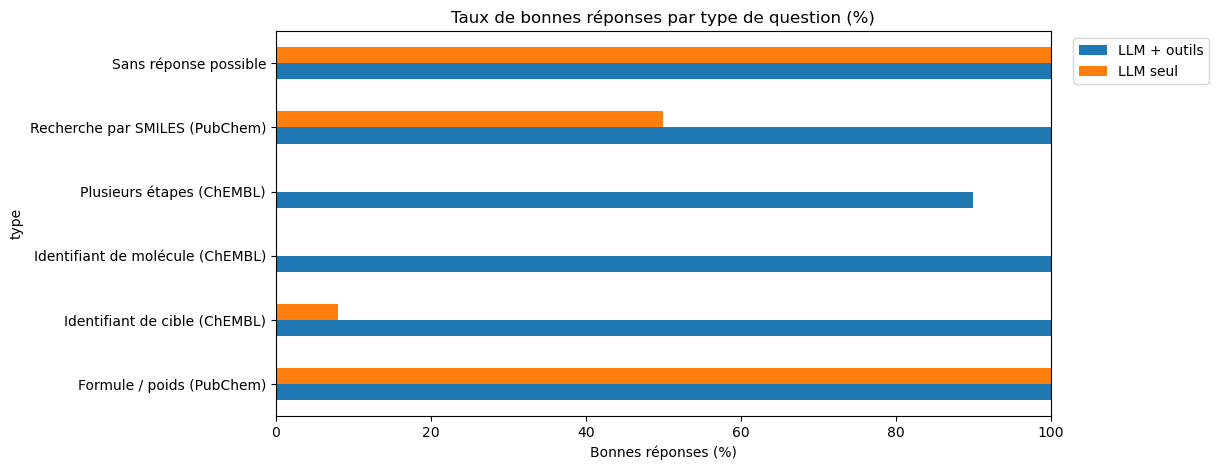

In [9]:
df = pd.DataFrame(resultats)

# 1) Nombre de réponses par statut
global_statuts = df.groupby("condition")["statut"].value_counts().unstack(fill_value=0)
global_statuts["total"] = global_statuts.sum(axis=1)
global_statuts["taux correct (%)"] = (100 * global_statuts.get("correct", 0) / global_statuts["total"]).round(1)
display(global_statuts)

def n_sur_N(s):
    return f"{int(s.sum())}/{len(s)}"

# 2) Par type de question, puis par langue
display(df.groupby(["type", "condition"])["correct"].agg(n_sur_N).unstack())
display(df.groupby(["langue", "condition"])["correct"].agg(n_sur_N).unstack())

# 3) Graphique pour le poster
par_type = (df.pivot_table(index="type", columns="condition",
                           values="correct", aggfunc="mean") * 100).round(0)
ax = par_type.plot(kind="barh", figsize=(10, 5), title="Taux de bonnes réponses par type de question (%)")
ax.set_xlim(0, 100)
ax.set_xlabel("Bonnes réponses (%)")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
ax.get_figure().savefig("resultats_par_type.png", dpi=200, bbox_inches="tight")

# 4) Sources citées (réponses avec outils, hors pièges)
def source_citee(rep):
    return bool(re.search(r"chembl\d+|cid\W{0,3}\d+", normaliser(rep)))

df["source_citee"] = df["reponse"].apply(source_citee)
avec = df[(df["condition"] == "LLM + outils") & (df["type"] != T_PIEGE)]
print(f"{avec['source_citee'].sum()}/{len(avec)} réponses avec outils citent un identifiant")

# 5) Langue de la réponse (mots-clés sensibles aux accents : molecule = EN, molécule = FR)
MOTS_EN = {"the", "is", "are", "of", "and", "for", "with", "was", "were", "this", "that",
           "in", "on", "no", "not", "found", "target", "molecule", "most", "potent",
           "formula", "molecular", "weight", "identifier", "distinct", "molecules", "tested",
           "measurements", "inhibitor", "has", "have", "been", "by", "could", "be"}
MOTS_FR = {"le", "la", "les", "est", "sont", "de", "des", "du", "et", "pour", "avec", "une",
           "un", "dans", "sur", "aucune", "aucun", "pas", "plus", "puissants", "protéine",
           "formule", "chimique", "poids", "moléculaire", "molécule", "molécules", "distinctes",
           "testées", "mesures", "identifiant", "cible", "trouvée", "trouvé", "inhibiteur",
           "selon", "été", "ont"}

def langue_reponse(rep):
    """Langue d'une réponse. Mots-clés sensibles aux accents (molecule / molécule).
    Une réponse « télégraphique » (formule + poids + source) est reconnue grâce à ses
    libellés (formule chimique, poids moléculaire) ; sinon : « indéterminée »."""
    mots = re.findall(r"[a-zàâçéèêëîïôûùüÿœ']+", normaliser(rep))
    n_en = sum(m in MOTS_EN for m in mots)
    n_fr = sum(m in MOTS_FR for m in mots)
    if n_en == n_fr:
        return "indéterminée"
    return "Anglais" if n_en > n_fr else "Français"

df["langue_reponse"] = df["reponse"].apply(langue_reponse)
avec_outils = df[df["condition"] == "LLM + outils"]
print(pd.crosstab(avec_outils["langue"], avec_outils["langue_reponse"]))

df.to_csv("resultats_evaluation.csv", index=False, encoding="utf-8-sig")

In [10]:
from collections import Counter

# 1) Les réponses « LLM + outils » qui ne sont pas correctes
faux = [r for r in resultats if r["condition"] == "LLM + outils" and r["statut"] != "correct"]
print(f"===== {len(faux)} réponse(s) avec outils non correcte(s) =====\n")
for r in faux:
    print(f'[question {r["id"]} | {r["langue"]} | {r["type"]}] statut = {r["statut"]}')
    print("QUESTION  :", r["question"])
    print("RÉFÉRENCE :", r["reference"])
    print("OUTILS    :", r["outils"])
    print("RÉPONSE   :", r["reponse"])
    print("-" * 80)

# 2) Réponses françaises dont la langue détectée diffère de la majorité
print("\n===== Langue détectée pour les réponses françaises avec outils =====")
fr = [r for r in resultats if r["condition"] == "LLM + outils" and r["langue"] == "Français"]
detections = [langue_reponse(r["reponse"]) for r in fr]
majoritaire = Counter(detections).most_common(1)[0][0]
for r, d in zip(fr, detections):
    if d != majoritaire:
        print(f'[question {r["id"]} | détecté : {d}]')
        print("RÉPONSE :", r["reponse"])
print("Terminé :", Counter(detections))

===== 1 réponse(s) avec outils non correcte(s) =====

[question 20 | Anglais | Plusieurs étapes (ChEMBL)] statut = faux
QUESTION  : How many molecules have been tested against the protein EGFR in ChEMBL?
RÉFÉRENCE : 19118 molécules distinctes (API ChEMBL, 2026-10-14)
OUTILS    : rechercher_cible_chembl, compter_activites
RÉPONSE   : One hundred ninety‑one thousand eighteen distinct molecules have been tested against EGFR, with a total of fifty‑eight thousand eight hundred forty‑seven activity measurements (ChEMBL, target CHEMBL203).
--------------------------------------------------------------------------------

===== Langue détectée pour les réponses françaises avec outils =====
Terminé : Counter({'Français': 30})


In [19]:
pd.set_option("display.max_colwidth", None)
df = pd.DataFrame(resultats)
df["langue_reponse"] = df["reponse"].apply(langue_reponse)

avec_outils = df["condition"] == "LLM + outils"
seul = df["condition"] == "LLM seul"
a_lire = df[
    (avec_outils & (df["statut"] != "correct"))
    | (seul & df["type"].isin([T_FORMULE, T_PIEGE]) & (df["statut"] != "correct"))
    | (avec_outils & (df["langue"] == "Anglais") & (df["langue_reponse"] == "Français"))
    | (avec_outils & (df["type"] == T_SMILES))
]
for _, r in a_lire.iterrows():
    print(f'[{r["id"]}] {r["langue"]} | {r["condition"]} | statut : {r["statut"]} | réponse détectée en : {r["langue_reponse"]}')
    print("Question :", r["question"][:110])
    print("Outils   :", r["outils"])
    print(r["reponse"])
    print("-" * 70)

[20] Anglais | LLM + outils | statut : faux | réponse détectée en : Anglais
Question : How many molecules have been tested against the protein EGFR in ChEMBL?
Outils   : rechercher_cible_chembl, compter_activites
One hundred ninety‑one thousand eighteen distinct molecules have been tested against EGFR, with a total of fifty‑eight thousand eight hundred forty‑seven activity measurements (ChEMBL, target CHEMBL203).
----------------------------------------------------------------------
[23] Anglais | LLM + outils | statut : correct | réponse détectée en : Anglais
Question : Is this molecule known in PubChem? Does it have reported biological activities? Give its CID. SMILES: COC1=C(C
Outils   : molecule_par_smiles
The molecule is known in PubChem and has reported biological activities.

- CID (PubChem): 123631【PubChem CID 123631】  
- Number of active assays: 1517【PubChem CID 123631】
----------------------------------------------------------------------
[23] Français | LLM + outils | statut

In [20]:
print(len(resultats), "lignes en mémoire")
print(pd.read_csv("resultats_evaluation.csv", encoding="utf-8-sig")
        .groupby(["langue", "condition"]).size())

120 lignes en mémoire
langue    condition   
Anglais   LLM + outils    30
          LLM seul        30
Français  LLM + outils    30
          LLM seul        30
dtype: int64
